<a href="https://colab.research.google.com/github/Kalyani-asekar/ot_practicals/blob/main/OTMINIPROJECT_10.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

┌──────────────────────────────────────────────────────────────┐
│           NUTRITION & COST OPTIMIZATION DASHBOARD            │
├──────────────────────────────────────────────────────────────┤
│ Total Daily Diet Cost : $8.10                                │
├──────────────────────────────────────────────────────────────┤
│ Food Item        │ Servings │ Cost/Serv │ Total Cost ($)   │
├──────────────────┼──────────┼───────────┼──────────────────┤
│ Oatmeal          │     4.00 │ $    0.50 │ $           2.00 │
│ Milk             │     2.49 │ $    0.80 │ $           1.99 │
│ Rice & Beans     │     3.00 │ $    1.20 │ $           3.60 │
│ Chicken          │     0.00 │ $    2.50 │ $           0.00 │
│ Spinach          │     0.00 │ $    1.50 │ $           0.00 │
│ Orange           │     0.86 │ $    0.60 │ $           0.51 │
├──────────────────┴──────────┴───────────┴──────────────────┤
│ NUTRIENT SUMMARY METRICS                                   │
├──────────────────┬─────────────┬───────────

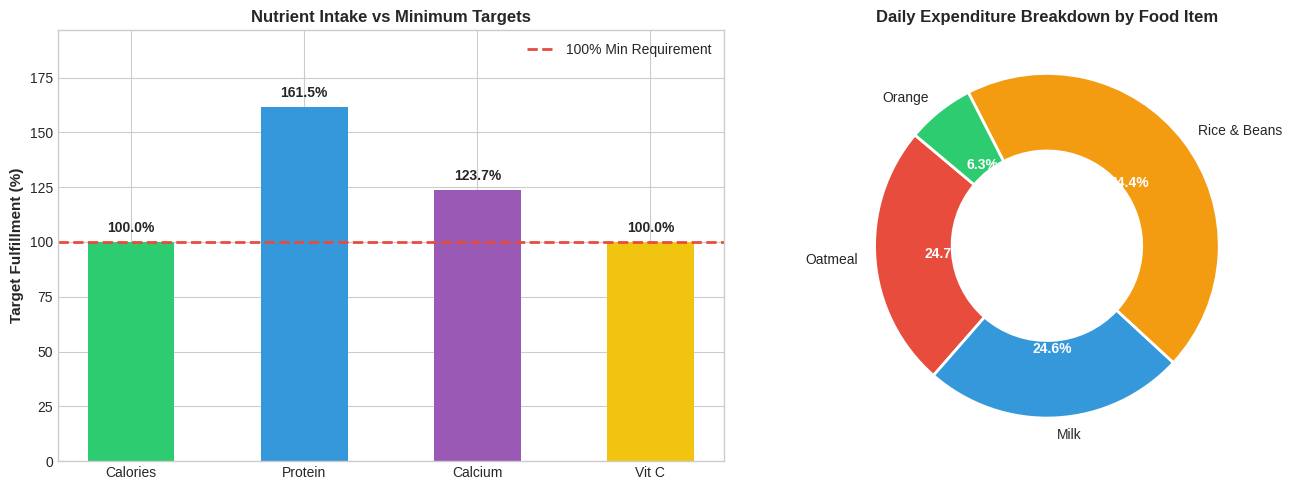

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import linprog

costs = [0.50, 0.80, 1.20, 2.50, 1.50, 0.60]
foods = ["Oatmeal", "Milk", "Rice & Beans", "Chicken", "Spinach", "Orange"]

A_nutrients = np.array([
    [150, 120, 350, 200, 40, 60],
    [6, 8, 12, 30, 3, 1],
    [20, 300, 40, 15, 100, 50],
    [0, 0, 0, 0, 30, 70],
    [2, 100, 400, 80, 70, 0],
    [3, 5, 2, 4, 0.5, 0.2]
])

A_ub = np.vstack([
    -A_nutrients[0],
    -A_nutrients[1],
    -A_nutrients[2],
    -A_nutrients[3],
    A_nutrients[4],
    A_nutrients[5]
])

b_ub = [-2000, -50, -800, -60, 2300, 70]
bounds = [(0, 4), (0, 3), (0, 3), (0, 3), (0, 3), (0, 3)]

res = linprog(c=costs, A_ub=A_ub, b_ub=b_ub, bounds=bounds, method='highs')

servings = res.x
total_cost = res.fun
actual_nutrients = A_nutrients @ servings

nutrient_names = ["Calories", "Protein", "Calcium", "Vit C", "Sodium", "Fat"]
targets = [2000, 50, 800, 60, 2300, 70]
units = ["kcal", "g", "mg", "mg", "mg", "g"]
limits_type = ["Min", "Min", "Min", "Min", "Max", "Max"]

item_costs = [s * c for s, c in zip(servings, costs)]

print("┌" + "─"*62 + "┐")
print("│" + "  NUTRITION & COST OPTIMIZATION DASHBOARD  ".center(62) + "│")
print("├" + "─"*62 + "┤")
print(f"│ Total Daily Diet Cost : ${total_cost:.2f}".ljust(63) + "│")
print("├" + "─"*62 + "┤")
print("│ Food Item        │ Servings │ Cost/Serv │ Total Cost ($)   │")
print("├──────────────────┼──────────┼───────────┼──────────────────┤")
for f, s, c, tc in zip(foods, servings, costs, item_costs):
    print(f"│ {f:<16} │ {s:8.2f} │ ${c:8.2f} │ ${tc:15.2f} │")
print("├──────────────────┴──────────┴───────────┴──────────────────┤")
print("│ NUTRIENT SUMMARY METRICS                                   │")
print("├──────────────────┬─────────────┬─────────────┬─────────────┤")
print("│ Nutrient         │ Target      │ Actual      │ Status      │")
print("├──────────────────┼─────────────┼─────────────┼─────────────┤")
for n, t, a, u, lt in zip(nutrient_names, targets, actual_nutrients, units, limits_type):
    status = "MET [OK]" if ((lt == "Min" and a >= t) or (lt == "Max" and a <= t)) else "EXCEEDED"
    print(f"│ {n:<16} │ {t:5} {u:<4} │ {a:7.1f} {u:<3} │ {status:<11} │")
print("└" + "─"*62 + "┘")

plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

pct = [(a / t) * 100 for a, t in zip(actual_nutrients[:4], targets[:4])]
bars = ax1.bar(nutrient_names[:4], pct, color=['#2ecc71', '#3498db', '#9b59b6', '#f1c40f'], width=0.5)
ax1.axhline(100, color='#e74c3c', linestyle='--', linewidth=2, label='100% Min Requirement')
ax1.set_ylabel('Target Fulfillment (%)', fontsize=11, fontweight='bold')
ax1.set_title('Nutrient Intake vs Minimum Targets', fontsize=12, fontweight='bold')
ax1.set_ylim(0, max(pct) + 35)
ax1.legend(loc='upper right')

for bar in bars:
    yval = bar.get_height()
    ax1.text(bar.get_x() + bar.get_width()/2.0, yval + 3, f'{yval:.1f}%', ha='center', va='bottom', fontweight='bold')

active_foods = [f for f, tc in zip(foods, item_costs) if tc > 0.001]
active_costs = [tc for tc in item_costs if tc > 0.001]

wedges, texts, autotexts = ax2.pie(
    active_costs,
    labels=active_foods,
    autopct='%1.1f%%',
    startangle=140,
    colors=['#e74c3c', '#3498db', '#f39c12', '#2ecc71'],
    wedgeprops=dict(width=0.45, edgecolor='white', linewidth=2)
)
for autotext in autotexts:
    autotext.set_color('white')
    autotext.set_weight('bold')

ax2.set_title('Daily Expenditure Breakdown by Food Item', fontsize=12, fontweight='bold')

plt.tight_layout()
plt.show()